# Bước 4 — Xây dựng Mô hình Học máy (Machine Learning)

**Đề tài:** Phân tích & dự báo giá thuê nhà trọ/căn hộ **theo khu vực** — *Nhập môn Khoa học Dữ liệu (IT4142)*

Notebook thực hiện **Bước 4** trong vòng đời Khai phá Tri thức (Slide L7): từ dữ liệu đã làm
sạch (Bước 2 — notebook `02_data_cleaning.ipynb`) và những hiểu biết từ EDA (Bước 3 — notebook
`03_eda.ipynb`), ta **huấn luyện và tinh chỉnh 5 mô hình hồi quy** để dự báo `price` (giá thuê,
triệu VNĐ/tháng), rồi chọn ra mô hình tốt nhất.

| Yếu tố | Giá trị |
|---|---|
| **Task (T)** | Dự đoán giá thuê nhà trọ/căn hộ |
| **Loại bài toán** | **Hồi quy** — đầu ra `y = price` là số thực liên tục |
| **Performance (P)** | MAE, RMSE, R² (đánh giá trên Validation; Test để dành Bước 5) |
| **Experience (E)** | `v2/data/processed/rental_data_clean.csv` (≈133.6k bản ghi, đã lọc `price≤17`, `area≤180`) |

### 5 thuật toán (nguyên tắc *No-Free-Lunch* — phải thử nhiều rồi so sánh)
1. **OLS** (hồi quy tuyến tính thường) — *baseline*.
2. **Ridge** (L2) — phạt `λ‖w‖²`, luôn có nghiệm, giảm overfitting.
3. **LASSO** (L1) — phạt `λ‖w‖₁`, tạo nghiệm thưa ⇒ tự chọn đặc trưng.
4. **Random Forest** — bagging nhiều cây, mạnh với quan hệ phi tuyến.
5. **XGBoost** — gradient boosting có regularization + early stopping.

> **Bám sát kết quả EDA (Bước 3):**
> - Đề tài là *"theo khu vực"* ⇒ tách `city`/`district` từ `full_address` làm đặc trưng chính.
> - Nghịch lý Simpson theo nguồn (EDA 9.2): `source` **cố ý KHÔNG dùng** làm đặc trưng — nó là
>   artifact thu thập dữ liệu, không phải yếu tố định giá thực; ưu tiên mô hình **tổng quát hóa**
>   theo đặc điểm BĐS thật (diện tích, khu vực, tiện ích) thay vì dựa vào "tin lấy ở web nào".
> - `price` lệch phải ⇒ EDA 5.2 gợi ý thử `log(price)`; **thực nghiệm đối sánh 11.2 bác bỏ**
>   (log chỉ cải thiện MAE nhẹ, làm RMSE/R² và phân khúc giá cao tệ hơn) ⇒ **mọi mô hình học
>   trên `price` gốc**.
> - Feature engineering tái sử dụng `v2/script/model/features.py` để **đồng bộ với app demo (Bước 6)**.
> - 🔗 Cờ tiện ích bị chế tác đã được **kiểm toán ở Bước 2** (notebook 02 v2, mục 7); ở đây ta
>   **áp dụng** kết quả đó (mask MNAR + ràng buộc đơn điệu).
>
> **Theo góp ý giảng viên**, mục **11** bổ sung 3 **thực nghiệm đối sánh (ablation)**:
> (11.1) dữ liệu thô ↔ Feature Engineering ↔ FE + PCA (kèm có/không chuẩn hóa);
> (11.2) mục tiêu `price` gốc ↔ `log(price)`; (11.3) có ↔ không lọc outlier.


## 0. Thiết lập môi trường

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
import sklearn, xgboost
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------- Bảng màu thống nhất với notebook EDA ----------
PALETTE = ["#2D5BFF", "#00C2A8", "#FF8C42", "#E5446D", "#7B61FF", "#FFC857"]
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
sns.set_palette(sns.color_palette(PALETTE))
matplotlib.rcParams.update({
    "font.family": "DejaVu Sans", "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlepad": 12,
    "axes.labelsize": 11, "axes.edgecolor": "#555", "grid.alpha": 0.30,
})

# ---------- Đường dẫn (v2-local) ----------
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parents[1]                           # → .../btl_khdl
sys.path.insert(0, str(ROOT / "v2" / "script" / "model"))
import features as F                                 # feature engineering dùng chung (v2)

DATA   = ROOT / "v2" / "data" / "processed"          # đầu vào: sản phẩm Bước 2 (v2)
FIG    = ROOT / "v2" / "docs" / "model"
MODELS = ROOT / "v2" / "models"
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

def save_mpl(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight", facecolor="white")

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)
print("DATA ->", DATA)
print("PNG  ->", FIG)
print("Mô hình ->", MODELS)

scikit-learn 1.9.0 | xgboost 3.2.0
DATA -> /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/data/processed
PNG  -> /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/docs/model
Mô hình -> /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/models


## 1. Nạp dữ liệu & Chuẩn bị đặc trưng (X) và mục tiêu (y)

Tái sử dụng `features.build_Xy()` — tách `city`/`district`, **mask cờ tiện ích chế tác (MNAR)**,
rồi gom các nhóm cột đầu vào. **Cố ý loại** các cột gây rò rỉ nhãn hoặc nhiễu:

| Cột bị loại | Lý do |
|---|---|
| `source` | **nguồn web cào** chỉ là *artifact thu thập dữ liệu*, không phải yếu tố định giá thực; app demo cũng không có input này ⇒ cố ý loại để mô hình học từ đặc điểm BĐS, không từ "tin lấy ở web nào" |
| `n_features` | tổng của 12 cờ tiện ích, nhưng **7/12 cờ bị chế tác** với đa số nguồn (xem MNAR bên dưới) ⇒ phép đếm vô nghĩa, lại còn mang "dấu vân tay nguồn" |
| `price_per_m2`, `log_price` | suy ra từ `price` ⇒ **rò rỉ nhãn** (data leakage) |
| `posted_date` | ~46% là sentinel ngày tương lai (EDA 3.2) |
| `description`, `detail_link` | thiếu phần lớn / không mang tín hiệu giá |
| `full_address` | đã thay bằng `city` + `district` |

**MNAR — cờ tiện ích bị chế tác khi gộp nguồn (đã kiểm toán ở Bước 2, notebook 02 v2):** đối
chiếu raw ↔ combined cho thấy chỉ **5 cờ** có cột gốc thật ở đa số nguồn (máy lạnh, máy giặt,
nước nóng, bảo vệ, hầm xe); 7 cờ còn lại chỉ thật ở `phongtro123`/`lozido` (~3% dữ liệu), với
các nguồn khác chúng được **điền ngẫu nhiên** lúc gộp (corr với giá trong từng nguồn ≈ 0);
`chothuenhadattoanvn` + `github_hcm/hn/dn` không có cờ thật nào. `mask_fabricated()` chuyển các
ô chế tác thành **NaN** ("không khai báo" ≠ "không có") — XGBoost/Random Forest xử lý NaN native,
mô hình tuyến tính dùng imputer.

**Đặc trưng đưa vào mô hình:**
- **Số** (chuẩn hóa Z-score): `area`, `bedrooms`, `bathrooms`.
- **Danh mục** (One-Hot, gộp hạng mục hiếm): `city`, `district`.
- **Nhị phân**: 12 cờ tiện ích `feature_*` (0/1; NaN nếu nguồn không khai báo).


In [2]:
rental = pd.read_csv(DATA / "rental_data_clean.csv", low_memory=False)
X, y, COL_GROUPS = F.build_Xy(rental)        # mask_mnar=True mặc định: cờ chế tác -> NaN

print(f"X: {X.shape[0]:,} dòng × {X.shape[1]} cột đầu vào (trước One-Hot)")
print(f"y = price: min={y.min()}, median={y.median()}, mean={y.mean():.2f}, max={y.max()} (triệu/tháng)")
print("Nhóm cột:", {k: len(v) for k, v in COL_GROUPS.items()})
print("  • num:", COL_GROUPS["num"])
print("  • cat:", COL_GROUPS["cat"])
print("  • bin:", len(COL_GROUPS["bin"]), "cờ tiện ích feature_*")
nan_share = X[COL_GROUPS["bin"]].isna().mean().sort_values()
print(f"\nTỷ lệ NaN sau mask MNAR: {nan_share.min()*100:.0f}% (cờ thật nhiều nguồn) "
      f"→ {nan_share.max()*100:.0f}% (cờ chỉ thật ở phongtro123/lozido)")
X.head(3)

X: 133,586 dòng × 17 cột đầu vào (trước One-Hot)
y = price: min=0.5, median=4.0, mean=4.80, max=17.0 (triệu/tháng)
Nhóm cột: {'num': 3, 'cat': 2, 'bin': 12}
  • num: ['area', 'bedrooms', 'bathrooms']
  • cat: ['city', 'district']
  • bin: 12 cờ tiện ích feature_*

Tỷ lệ NaN sau mask MNAR: 17% (cờ thật nhiều nguồn) → 98% (cờ chỉ thật ở phongtro123/lozido)


,area,bedrooms,bathrooms,city,district,feature_Đầy đủ nội thất,feature_Có gác,feature_Có kệ bếp,feature_Có máy lạnh,feature_Có máy giặt,feature_Có tủ lạnh,feature_Có thang máy,feature_Không chung chủ,feature_Giờ giấc tự do,feature_Có bảo vệ 24/24,feature_Có hầm để xe,feature_Có nước nóng
0,20.0,4,1,Hà Nội,Quận Nam Từ Liêm,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,NaN
1,20.0,2,5,Hà Nội,Quận Thanh Xuân,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,NaN
2,35.0,1,2,Hà Nội,Quận Bắc Từ Liêm,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,NaN


## 2. Chia Train / Validation / Test = 70 / 15 / 15

Phương pháp **Hold-out** (Slide L12): chia 3 tập với vai trò tách bạch để tránh "nhìn trộm" Test
trong lúc chọn mô hình:

| Tập | Tỷ lệ | Vai trò |
|---|---|---|
| **Train** | 70% | Huấn luyện + Cross-Validation để **tinh chỉnh siêu tham số** |
| **Validation** | 15% | **So sánh & chọn** mô hình tốt nhất (Model Selection) |
| **Test** | 15% | 🔒 **Giữ nguyên** — chỉ dùng 1 lần ở **Bước 5** (Model Assessment) |


In [3]:
# Tách Test (15%) trước, phần còn lại (85%) tách tiếp thành Train (70%) + Val (15%)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.176, random_state=RANDOM_STATE)  # 0.176×0.85 ≈ 0.15

for name, part in [("Train", X_train), ("Validation", X_val), ("Test 🔒", X_test)]:
    print(f"{name:12s}: {len(part):>7,} mẫu ({len(part)/len(X)*100:4.1f}%)")
print("\n⚠️  Tập Test sẽ KHÔNG được dùng trong notebook này (để dành Bước 5).")

Train       :  93,563 mẫu (70.0%)
Validation  :  19,985 mẫu (15.0%)
Test 🔒      :  20,038 mẫu (15.0%)

⚠️  Tập Test sẽ KHÔNG được dùng trong notebook này (để dành Bước 5).


## 3. Tiền xử lý dùng chung + quyết định về biến mục tiêu

Một `ColumnTransformer` **duy nhất** dùng cho cả 5 mô hình (nhất quán, chống lệch):

- **Số** → `StandardScaler` (bắt buộc cho mô hình tuyến tính có phạt; vô hại với cây).
- **Danh mục** → `OneHotEncoder` **gộp hạng mục hiếm** (`min_frequency=100`) để chặn bùng nổ
  chiều do `district` / `city` cardinality cao, đồng thời xử lý được hạng mục lạ khi dự đoán
  (app demo).
- **Nhị phân** (0/1 hoặc NaN sau mask MNAR) → mô hình cây: passthrough (XGBoost/RF xử lý NaN
  native, học riêng nhánh "không khai báo"); mô hình tuyến tính: `SimpleImputer(mean)` vì
  OLS/Ridge/LASSO không nhận NaN (mean = tỷ lệ quan sát được — trung hòa, không thiên lệch dấu).

**Biến mục tiêu giữ NGUYÊN `price` (triệu/tháng):** EDA 5.2 cho thấy `price` lệch phải và gợi ý
thử `log(price)`. Tuy nhiên, các mức giá cao đều có **nguyên nhân thực** (vị trí trung tâm, căn
hộ đầy đủ tiện ích…) — nén chúng bằng log có nguy cơ làm mô hình *underweight* phân khúc giá cao.
**Thực nghiệm đối sánh ở mục 11.2** xác nhận đúng điều đó: log chỉ cải thiện MAE nhẹ, còn
RMSE/R² **và** sai số phân khúc giá cao đều **tệ hơn** ⇒ cả 5 mô hình học **trực tiếp trên
`price` gốc**, mọi chỉ số tự nhiên cùng đơn vị triệu/tháng nên so sánh công bằng.


In [4]:
def build_prep(impute_bin=False):
    "ColumnTransformer mới (chưa fit). impute_bin=True cho mô hình tuyến tính (không nhận NaN)."
    return F.build_preprocessor(COL_GROUPS, min_frequency=100, impute_bin=impute_bin)

def make_linear(step_name, estimator):
    "Pipeline tuyến tính: prep (impute NaN cờ tiện ích) -> estimator, học trên price gốc (xem 11.2)."
    return Pipeline([("prep", build_prep(impute_bin=True)), (step_name, estimator)])

def evaluate(model, Xe, ye):
    "Trả về MAE / RMSE / R² (đơn vị: triệu VNĐ/tháng)."
    pred = model.predict(Xe)
    return {"MAE": mean_absolute_error(ye, pred),
            "RMSE": root_mean_squared_error(ye, pred),
            "R2": r2_score(ye, pred)}

# Minh họa: One-Hot biến các cột danh mục/số thành bao nhiêu chiều?
_demo = build_prep().fit(X_train)
enc_names = list(_demo.get_feature_names_out())
print(f"Sau tiền xử lý: {X_train.shape[1]} cột → {len(enc_names)} chiều đặc trưng.")
print("Ví dụ tên chiều:", enc_names[:4], "...", enc_names[-3:])

results = {}          # gom kết quả Validation của từng mô hình
models  = {}          # gom pipeline đã-tinh-chỉnh của từng mô hình
CV_TUNE    = 5        # số fold CV khi tinh chỉnh mô hình tuyến tính (Grid)
CV_TREE    = 3        # số fold CV khi tinh chỉnh mô hình cây (Random)
RF_N_ITER  = 12       # số cấu hình RandomizedSearch thử cho Random Forest
XGB_N_ITER = 25       # số cấu hình RandomizedSearch thử cho XGBoost
print(f"\nSẵn sàng huấn luyện. CV tuyến tính={CV_TUNE} fold; CV cây={CV_TREE} fold.")

Sau tiền xử lý: 17 cột → 72 chiều đặc trưng.
Ví dụ tên chiều: ['area', 'bedrooms', 'bathrooms', 'city_Bình Dương'] ... ['feature_Có bảo vệ 24/24', 'feature_Có hầm để xe', 'feature_Có nước nóng']

Sẵn sàng huấn luyện. CV tuyến tính=5 fold; CV cây=3 fold.


## 4. Mô hình 1 — Hồi quy tuyến tính OLS *(baseline)*

Tìm `f(x)=w₀+w₁x₁+…+wₙxₙ` cực tiểu **RSS** `Σ(yᵢ−ŷᵢ)²`; nghiệm chuẩn `w*=(AᵀA)⁻¹Aᵀy`.
**Nhược điểm:** dễ overfitting, hỏng khi `AᵀA` suy biến (đa cộng tuyến) — chính là lý do cần
Ridge/LASSO ở dưới. Đây là mốc tham chiếu để đo mức cải thiện của các mô hình sau.


In [5]:
ols = make_linear("ols", LinearRegression())
ols.fit(X_train, y_train)
results["OLS"] = evaluate(ols, X_val, y_val); models["OLS"] = ols
print("OLS — Validation:", {k: round(v, 4) for k, v in results["OLS"].items()})

OLS — Validation: {'MAE': 1.9633, 'RMSE': 2.5862, 'R2': 0.1947}


## 5. Mô hình 2 — Ridge (L2 Regularization)

Thêm phạt L2: `w* = argmin [Σ(yᵢ−Aᵢw)² + λ‖w‖₂²]`. Hạn chế độ lớn `w` ⇒ giảm overfitting và
**luôn tồn tại nghiệm**. Dò `α (=λ)` trên lưới `[0.01, 0.1, 1, 10, 100]` bằng GridSearchCV (CV
trên Train, chấm theo RMSE).


In [6]:
ridge_grid = {"ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]}
ridge_gs = GridSearchCV(make_linear("ridge", Ridge()), ridge_grid, cv=CV_TUNE,
                        scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
results["Ridge"] = evaluate(ridge_gs.best_estimator_, X_val, y_val)
models["Ridge"]  = ridge_gs.best_estimator_
print(f"Best α = {ridge_gs.best_params_['ridge__alpha']}")
print("Ridge — Validation:", {k: round(v, 4) for k, v in results["Ridge"].items()})

Best α = 1.0
Ridge — Validation: {'MAE': 1.9632, 'RMSE': 2.5862, 'R2': 0.1947}


## 6. Mô hình 3 — LASSO (L1 Regularization) + tự chọn đặc trưng

Thay L2 bằng L1: `w* = argmin [Σ(yᵢ−Aᵢw)² + λ‖w‖₁]`. L1 đẩy nhiều hệ số về **đúng 0** ⇒ nghiệm
**thưa**, đóng vai trò **bộ chọn đặc trưng tự động**. Dò `α` trên `[0.001, 0.01, 0.1, 1, 10]`.


In [7]:
lasso_grid = {"lasso__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]}
lasso_gs = GridSearchCV(make_linear("lasso", Lasso(max_iter=10000)), lasso_grid, cv=CV_TUNE,
                        scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
results["LASSO"] = evaluate(lasso_gs.best_estimator_, X_val, y_val)
models["LASSO"]  = lasso_gs.best_estimator_
best_a = lasso_gs.best_params_['lasso__alpha']

# Đếm đặc trưng bị LASSO loại (hệ số = 0) tại α tốt nhất
lin = lasso_gs.best_estimator_
coef = lin.named_steps["lasso"].coef_
names = lin.named_steps["prep"].get_feature_names_out()
n_zero = int((coef == 0).sum())
print(f"Best α = {best_a}")
print("LASSO — Validation:", {k: round(v, 4) for k, v in results['LASSO'].items()})
print(f"\nĐặc trưng bị loại (hệ số=0): {n_zero}/{len(coef)}  →  giữ lại {len(coef)-n_zero}.")
top_keep = pd.Series(coef, index=names).loc[lambda s: s != 0].abs().sort_values(ascending=False)
print("Top đặc trưng LASSO giữ lại (|hệ số| lớn nhất):")
print(top_keep.head(8).round(4).to_string())

Best α = 0.001
LASSO — Validation: {'MAE': 1.9657, 'RMSE': 2.5898, 'R2': 0.1924}

Đặc trưng bị loại (hệ số=0): 23/72  →  giữ lại 49.
Top đặc trưng LASSO giữ lại (|hệ số| lớn nhất):
district_Quận Hà Đông          2.2667
district_(không rõ)            1.7654
city_Đà Nẵng                   1.3864
city_Khánh Hòa                 1.3346
feature_Có bảo vệ 24/24        1.3022
city_Hà Nội                    0.9529
district_infrequent_sklearn    0.8898
area                           0.6942


## 7. Mô hình 4 — Random Forest

Ba thành phần (Slide L7): **(1) ngẫu nhiên hóa** thuộc tính tại mỗi nút, **(2) bagging** —
bootstrap mẫu cho từng cây, **(3) tổng hợp** — trung bình dự đoán các cây. Ít overfitting, mạnh
với quan hệ phi tuyến và tương tác giữa đặc trưng (rất hợp với hiệu ứng khu vực × diện tích).

Dò siêu tham số bằng **RandomizedSearchCV** (lấy mẫu ngẫu nhiên trên lưới — hiệu quả hơn duyệt
toàn bộ khi không gian lớn): `n_estimators∈{100,200,500}`, `max_depth∈{5,10,20,None}`,
`min_samples_split∈{2,5,10}`.


In [8]:
rf_dist = {"rf__n_estimators": [100, 200, 500],
           "rf__max_depth": [5, 10, 20, None],
           "rf__min_samples_split": [2, 5, 10]}
# Mỗi cây-rừng tự song song hóa trên mọi lõi (rf n_jobs=-1) còn search chạy tuần tự
# (search n_jobs=1): cấu hình này nhanh hơn nhiều cho RF vì việc dựng cây song song
# gần tuyến tính, tránh để một fit "500 cây / depth=None" bị kẹt 1 lõi.
rf_pipe = Pipeline([("prep", build_prep()),
                    ("rf", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
t0 = time.time()
rf_search = RandomizedSearchCV(rf_pipe, rf_dist, n_iter=RF_N_ITER, cv=CV_TREE,
                               scoring="neg_root_mean_squared_error",
                               n_jobs=1, random_state=RANDOM_STATE).fit(X_train, y_train)
results["Random Forest"] = evaluate(rf_search.best_estimator_, X_val, y_val)
models["Random Forest"]  = rf_search.best_estimator_
print(f"Best params: {rf_search.best_params_}  (dò trong {time.time()-t0:.0f}s)")
print("Random Forest — Validation:", {k: round(v, 4) for k, v in results['Random Forest'].items()})

Best params: {'rf__n_estimators': 200, 'rf__min_samples_split': 5, 'rf__max_depth': 10}  (dò trong 186s)
Random Forest — Validation: {'MAE': 1.0135, 'RMSE': 1.6775, 'R2': 0.6612}


## 8. Mô hình 5 — XGBoost (Extreme Gradient Boosting)

Boosting: mỗi cây mới học **sửa residual** của tổ hợp trước theo hướng gradient. Hàm mục tiêu =
**loss** (giảm sai số) + **regularization** (`reg_alpha` L1 + `reg_lambda` L2 kiểm soát độ phức
tạp cây). Ưu điểm: chính xác cao, xử lý tương tác phi tuyến, hỗ trợ **early stopping**.

Quy trình 2 bước:
1. **RandomizedSearchCV** dò lưới (`learning_rate, max_depth, subsample, colsample_bytree,
   reg_alpha, reg_lambda, n_estimators`) — chọn cấu hình tốt nhất theo CV-RMSE.
2. **Huấn luyện lại** cấu hình tốt nhất với `early_stopping_rounds=50` trên tập Validation: cho
   `n_estimators=2000` làm trần, XGBoost tự dừng khi val-RMSE ngừng cải thiện ⇒ chống overfitting
   và tiết kiệm cây. *(XGBoost 3.x: `early_stopping_rounds` đặt ở constructor, `eval_set` ở `fit`.)*

**Ràng buộc đơn điệu (`monotone_constraints`) cho 12 cờ tiện ích:** trong dữ liệu, tin giá rẻ
*quảng cáo* nhiều tiện ích còn căn hộ đắt thường *không liệt kê* — tương quan hành vi đăng tin,
không phải giá trị thật của tiện ích. Không ràng buộc, mô hình học "tick máy lạnh ⇒ giảm giá" —
phi lý với người dùng app. Ràng buộc +1 ép hiệu ứng tiện ích **không âm**; nhánh NaN ("không khai
báo") vẫn tự do nên mô hình không mất thông tin nguồn-khai-báo.


In [9]:
xgb_dist = {"xgb__n_estimators": [100, 300, 500],
            "xgb__learning_rate": [0.01, 0.03, 0.05, 0.1],
            "xgb__max_depth": [5, 7, 9, 10],     # mô hình RÀNG BUỘC ưa cây sâu hơn (probe 2026-06)
            "xgb__subsample": [0.6, 0.8, 1.0],
            "xgb__colsample_bytree": [0.6, 0.8, 1.0],
            "xgb__reg_alpha": [0, 0.1, 1],
            "xgb__reg_lambda": [1, 5, 10]}
MONO = F.monotone_constraints(COL_GROUPS)    # {12 cờ tiện ích: +1} — theo TÊN cột (prep xuất pandas)
xgb_pipe = Pipeline([("prep", build_prep()),
                     ("xgb", XGBRegressor(tree_method="hist", random_state=RANDOM_STATE,
                                          n_jobs=1, monotone_constraints=MONO))])
t0 = time.time()
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_dist, n_iter=XGB_N_ITER, cv=CV_TREE,
                                scoring="neg_root_mean_squared_error",
                                n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Best params: {xgb_search.best_params_}  (dò trong {time.time()-t0:.0f}s)")
val_search = evaluate(xgb_search.best_estimator_, X_val, y_val)
print("XGBoost (search) — Validation:", {k: round(v, 4) for k, v in val_search.items()})

Best params: {'xgb__subsample': 0.6, 'xgb__reg_lambda': 10, 'xgb__reg_alpha': 1, 'xgb__n_estimators': 100, 'xgb__max_depth': 10, 'xgb__learning_rate': 0.05, 'xgb__colsample_bytree': 1.0}  (dò trong 47s)
XGBoost (search) — Validation: {'MAE': 1.2608, 'RMSE': 1.8957, 'R2': 0.5673}


In [10]:
# --- Bước 2: refit cấu hình tốt nhất + EARLY STOPPING trên Validation ---
best = {k.replace("xgb__", ""): v for k, v in xgb_search.best_params_.items()}
prep_fit = build_prep().fit(X_train)                 # fit preprocessor trên Train
Xtr_t = prep_fit.transform(X_train)
Xval_t = prep_fit.transform(X_val)

xgb_final = XGBRegressor(
    tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1,
    early_stopping_rounds=50, n_estimators=2000,        # trần lớn; early stop tự cắt
    monotone_constraints=MONO,                          # giữ ràng buộc tiện ích không âm
    learning_rate=best["learning_rate"], max_depth=best["max_depth"],
    subsample=best["subsample"], colsample_bytree=best["colsample_bytree"],
    reg_alpha=best["reg_alpha"], reg_lambda=best["reg_lambda"])
xgb_final.fit(Xtr_t, y_train, eval_set=[(Xval_t, y_val)], verbose=False)

# Ghép lại thành Pipeline hoàn chỉnh (prep đã fit + xgb đã fit) để lưu/triển khai
xgb_model = Pipeline([("prep", prep_fit), ("xgb", xgb_final)])
results["XGBoost"] = evaluate(xgb_model, X_val, y_val); models["XGBoost"] = xgb_model
print(f"Early stopping dừng ở cây thứ {xgb_final.best_iteration} / 2000 "
      f"(search chọn n_estimators={best['n_estimators']}).")
print("XGBoost (early-stop) — Validation:", {k: round(v, 4) for k, v in results['XGBoost'].items()})

Early stopping dừng ở cây thứ 126 / 2000 (search chọn n_estimators=100).
XGBoost (early-stop) — Validation: {'MAE': 1.2556, 'RMSE': 1.8943, 'R2': 0.568}


## 9. So sánh trên Validation & chọn mô hình triển khai

Báo cáo theo **2 góc nhìn**, tất cả tính trên cùng tập Validation (đơn vị triệu VNĐ/tháng):

1. **Chính xác nhất:** RMSE thấp nhất (phạt nặng lỗi lớn) kết hợp R² cao nhất.
2. **Mô hình triển khai — chỉ số TỐT là cần, nhưng chưa đủ:** ngoài độ chính xác, app demo còn
   đòi hỏi *tick thêm tiện ích không được làm giảm giá dự báo* (chặn confound "tin rẻ quảng cáo
   tiện ích, căn hộ đắt không liệt kê" — xem mục 1 & 8), và mô hình phải **commit được lên GitHub
   (<100 MB) + suy luận nhanh** trong app. Cân nhắc:
   - **Random Forest** thường đạt RMSE thô thấp nhất, nhưng nặng **≈100 MB** (vượt giới hạn GitHub,
     nạp/dự đoán chậm trong app) — một phần độ chính xác đó đến từ *tự do khai thác tương quan
     phi nhân quả* mà ta muốn loại.
   - **XGBoost** ≈2 MB, có early stopping, và (như RF trong sklearn ≥1.4) hỗ trợ
     **`monotone_constraints`** — ta áp ràng buộc +1 cho 12 cờ tiện ích lên đúng mô hình triển khai.
   ⇒ `model_best.pkl` lưu **XGBoost (có ràng buộc đơn điệu)**: gọn, đúng hành vi cho app;
   RMSE của các mô hình không ràng buộc vẫn được báo cáo đầy đủ để so sánh trung thực.


,MAE,RMSE,R²
Random Forest,1.0135,1.6775,0.6612
XGBoost,1.2556,1.8943,0.5680
Ridge,1.9632,2.5862,0.1947
OLS,1.9633,2.5862,0.1947
LASSO,1.9657,2.5898,0.1924


📈 Chính xác nhất (RMSE thấp nhất): Random Forest
🏆 TRIỂN KHAI (lưu model_best.pkl): XGBoost — gọn (≈2 MB), early stopping, và mang
   ràng buộc đơn điệu (Quyết định D) bảo đảm 'tick tiện ích không giảm giá'.
   Random Forest (không ràng buộc) RMSE thấp hơn 12.9% — phần chênh đến từ việc
   tự do khai thác tương quan hành-vi-đăng-tin mà mô hình triển khai cố ý từ chối.


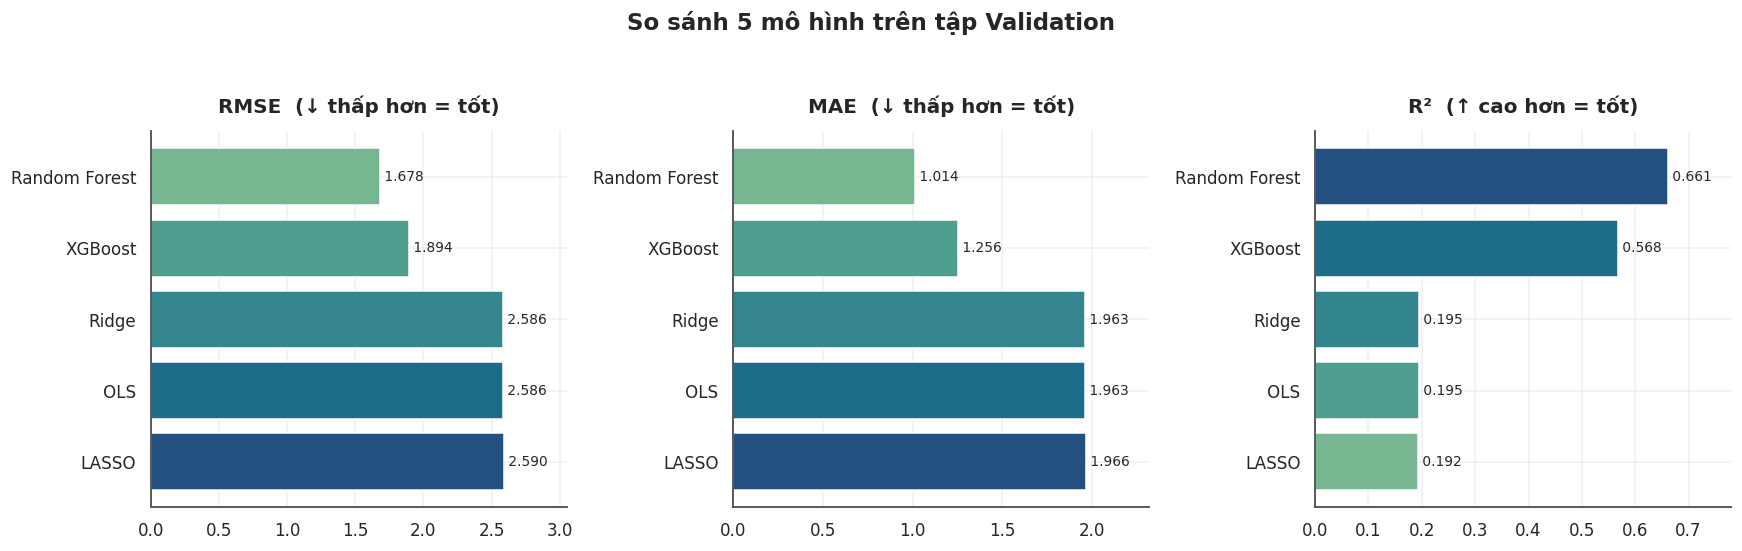

In [11]:
cmp = (pd.DataFrame(results).T[["MAE", "RMSE", "R2"]]
       .sort_values("RMSE").rename(columns={"R2": "R²"}))
MOST_ACCURATE = cmp.index[0]                      # RMSE thấp nhất (chính xác nhất)

# TRIỂN KHAI: XGBoost — gọn (≈2 MB vs RF ≈100 MB, commit GitHub + app nhanh), có early stopping,
# và mang RÀNG BUỘC ĐƠN ĐIỆU (Quyết định D) bảo đảm hiệu ứng tiện ích không âm. RMSE thô của RF
# có thể thấp hơn nhưng phần chênh đến từ khai thác tương quan hành-vi-đăng-tin phi nhân quả.
BEST_NAME = "XGBoost"

display(cmp.style.format("{:.4f}")
        .background_gradient(subset=["RMSE", "MAE"], cmap="crest_r")
        .background_gradient(subset=["R²"], cmap="crest")
        .set_caption("Hiệu năng trên Validation (sắp xếp theo RMSE tăng dần)"))
print(f"📈 Chính xác nhất (RMSE thấp nhất): {MOST_ACCURATE}")
print(f"🏆 TRIỂN KHAI (lưu model_best.pkl): {BEST_NAME} — gọn (≈2 MB), early stopping, và mang")
print("   ràng buộc đơn điệu (Quyết định D) bảo đảm 'tick tiện ích không giảm giá'.")
if BEST_NAME != MOST_ACCURATE:
    gap = (cmp.loc[BEST_NAME, 'RMSE'] - cmp['RMSE'].min()) / cmp['RMSE'].min() * 100
    print(f"   {MOST_ACCURATE} (không ràng buộc) RMSE thấp hơn {gap:.1f}% — phần chênh đến từ việc")
    print("   tự do khai thác tương quan hành-vi-đăng-tin mà mô hình triển khai cố ý từ chối.")

# Biểu đồ cột so sánh 3 chỉ số
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
order = cmp.index.tolist()
for ax, col, better, cmap in [(axes[0], "RMSE", "↓ thấp hơn = tốt", "crest_r"),
                              (axes[1], "MAE", "↓ thấp hơn = tốt", "crest_r"),
                              (axes[2], "R²",  "↑ cao hơn = tốt",  "crest")]:
    vals = cmp[col]
    colors = sns.color_palette(cmap, len(vals))
    bars = ax.barh(order[::-1], vals.reindex(order[::-1]), color=colors)
    for b, v in zip(bars, vals.reindex(order[::-1])):
        ax.text(v, b.get_y() + b.get_height()/2, f" {v:.3f}", va="center", fontsize=9)
    ax.set_title(f"{col}  ({better})")
    ax.margins(x=0.18)
fig.suptitle("So sánh 5 mô hình trên tập Validation", y=1.04, fontsize=15, fontweight="bold")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "01_model_comparison_val.png"); plt.show()

## 10. Feature Importance — đặc trưng nào chi phối giá thuê?

So sánh hai góc nhìn của hai mô hình cây:
- **Random Forest — MDI** (`feature_importances_`): mức giảm bất thuần (impurity) trung bình.
- **XGBoost — gain** (`importance_type="gain"`): mức giảm loss trung bình mỗi lần tách theo đặc trưng.

Lấy **top-10** mỗi mô hình để đối chiếu. Vì đã **loại `source`**, importance giờ phản ánh đúng
yếu tố định giá thực: **khu vực** (`city`/`district`), **diện tích** (`area`) và **tiện ích** lên
top — dễ diễn giải và đúng kỳ vọng nghiệp vụ.


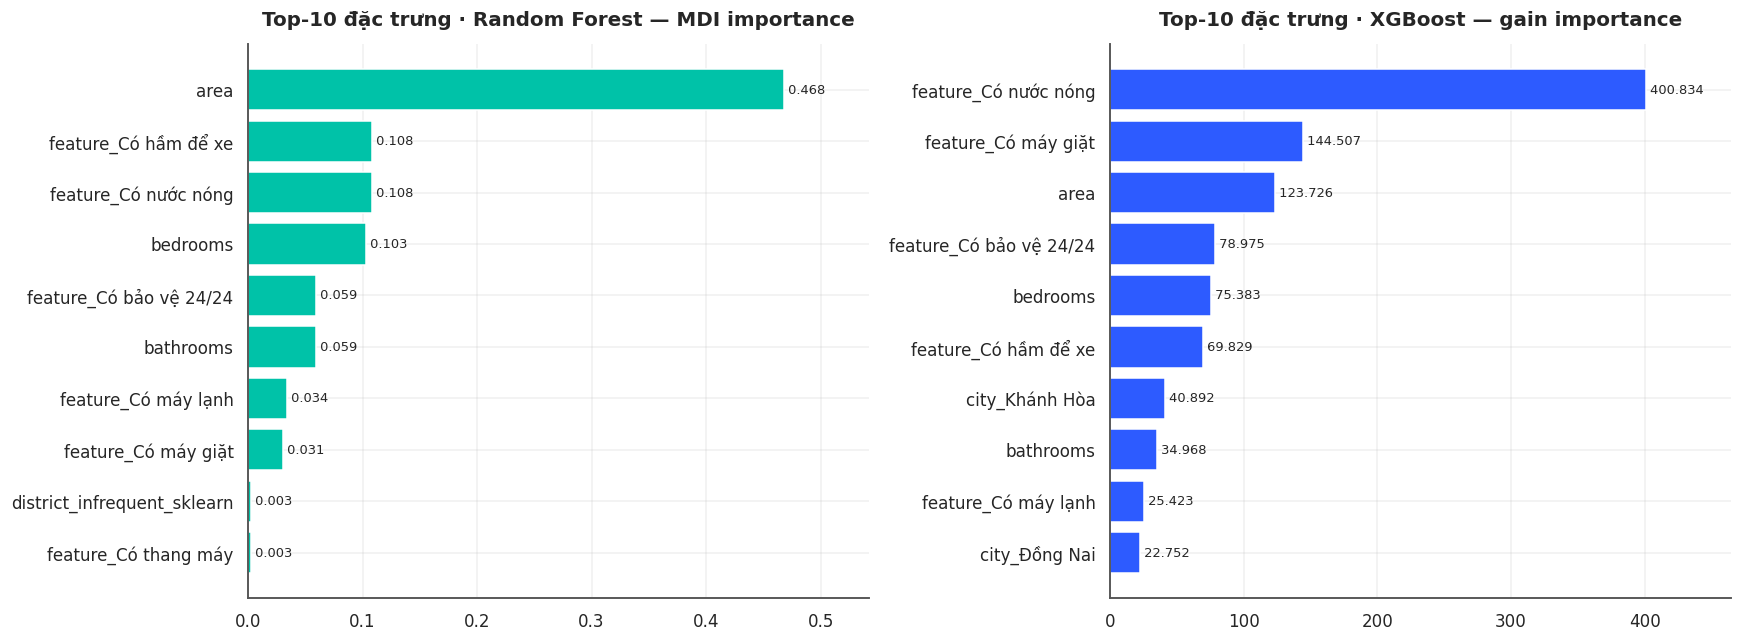

RF top-5 : ['area', 'feature_Có hầm để xe', 'feature_Có nước nóng', 'bedrooms', 'feature_Có bảo vệ 24/24']
XGB top-5: ['feature_Có nước nóng', 'feature_Có máy giặt', 'area', 'feature_Có bảo vệ 24/24', 'bedrooms']


In [12]:
# Random Forest MDI
rf_best = models["Random Forest"]
rf_names = rf_best.named_steps["prep"].get_feature_names_out()
rf_imp = (pd.Series(rf_best.named_steps["rf"].feature_importances_, index=rf_names)
          .sort_values(ascending=False).head(10))

# XGBoost gain. Preprocessor xuất pandas (set_output) nên booster lưu TÊN cột thật
# ('area', 'feature_*'…) thay vì 'f0/f1'. Xử lý cả 2 kiểu key để bền vững.
booster = models["XGBoost"].named_steps["xgb"].get_booster()
xgb_names = list(models["XGBoost"].named_steps["prep"].get_feature_names_out())
gain = booster.get_score(importance_type="gain")
def _featname(k):
    return xgb_names[int(k[1:])] if (k[0] == "f" and k[1:].isdigit()) else k
xgb_imp = (pd.Series({_featname(k): v for k, v in gain.items()})
           .sort_values(ascending=False).head(10))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, imp, title, color in [
    (axes[0], rf_imp, "Random Forest — MDI importance", PALETTE[1]),
    (axes[1], xgb_imp, "XGBoost — gain importance", PALETTE[0])]:
    bars = ax.barh(imp.index[::-1], imp.values[::-1], color=color)
    ax.set_title(f"Top-10 đặc trưng · {title}")
    ax.margins(x=0.16)
    for b, v in zip(bars, imp.values[::-1]):
        ax.text(v, b.get_y() + b.get_height()/2, f" {v:.3f}", va="center", fontsize=8.5)
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "02_feature_importance.png"); plt.show()

print("RF top-5 :", list(rf_imp.head().index))
print("XGB top-5:", list(xgb_imp.head().index))

### 10.1. Kiểm tra nhanh mô hình tốt nhất trên Validation

*Chẩn đoán sơ bộ* (không phải đánh giá cuối — Test để dành Bước 5): điểm bám sát đường `y = x`
là dự đoán tốt; phần dư (residual) phân tán quanh 0 ⇒ không thiên lệch hệ thống.


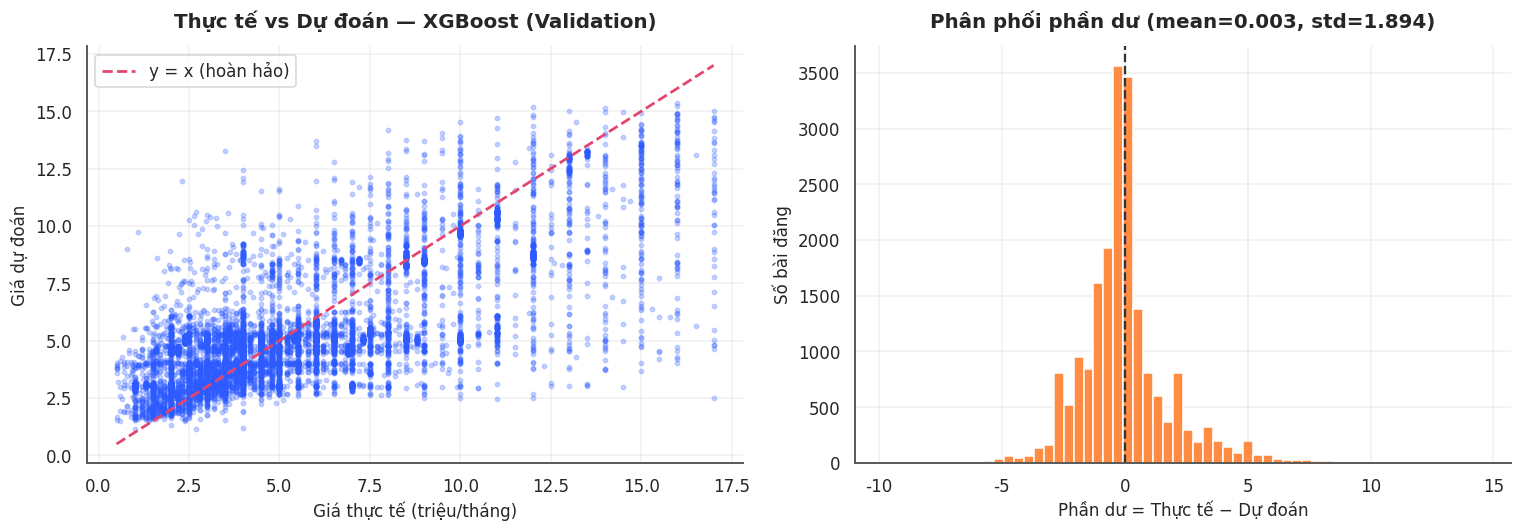

In [13]:
best_model = models[BEST_NAME]
pred_val = best_model.predict(X_val)
resid = y_val.values - pred_val

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_val, pred_val, s=8, alpha=0.25, color=PALETTE[0])
lims = [min(y_val.min(), pred_val.min()), max(y_val.max(), pred_val.max())]
axes[0].plot(lims, lims, "--", color="#E5446D", lw=1.8, label="y = x (hoàn hảo)")
axes[0].set_xlabel("Giá thực tế (triệu/tháng)"); axes[0].set_ylabel("Giá dự đoán")
axes[0].set_title(f"Thực tế vs Dự đoán — {BEST_NAME} (Validation)"); axes[0].legend()

axes[1].hist(resid, bins=60, color=PALETTE[2], edgecolor="white")
axes[1].axvline(0, color="#333", ls="--")
axes[1].set_xlabel("Phần dư = Thực tế − Dự đoán"); axes[1].set_ylabel("Số bài đăng")
axes[1].set_title(f"Phân phối phần dư (mean={resid.mean():.3f}, std={resid.std():.3f})")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "03_best_pred_vs_actual_val.png"); plt.show()

## 11. Thực nghiệm đối sánh (Ablation Studies) — theo góp ý giảng viên

Giảng viên yêu cầu **chứng minh bằng thực nghiệm** (chứ không chỉ lập luận) cho các quyết định
tiền xử lý / feature engineering. Mục này chạy **3 thí nghiệm đối sánh**, mỗi thí nghiệm chỉ
thay đổi **đúng một yếu tố** và giữ nguyên mọi thứ còn lại:

| Thí nghiệm | Yếu tố thay đổi | Trả lời góp ý |
|---|---|---|
| **11.1** | Đặc trưng: **thô → FE → FE+PCA** (kèm có/không **chuẩn hóa**) | "So sánh hiệu năng giữa dữ liệu thô và dữ liệu đã FE/PCA" |
| **11.2** | Biến mục tiêu: **`price` gốc ↔ `log(price)`** | "Log biến price có thực sự tăng hiệu năng, hay làm méo tín hiệu giá cao?" |
| **11.3** | Dữ liệu huấn luyện: **có ↔ không lọc outlier** | "Outlier (vd nhà 1.000 tỷ) giữ lại có làm sai lệch mô hình?" |

**Nguyên tắc so sánh công bằng:**
- Cùng phép chia Train/Validation (random_state=42) và cùng bộ chỉ số (MAE/RMSE/R², đơn vị
  **triệu VNĐ/tháng** gốc) — mọi biến thể được chấm trên **cùng một tập Validation**.
- **Siêu tham số đóng băng** theo cấu hình đã tinh chỉnh ở mục 4–8 (không dò lại cho từng biến
  thể) — như vậy chênh lệch quan sát được là do *yếu tố đang thử*, không phải do may rủi tuning.
- Dùng 3 mô hình đại diện: **OLS** (tuyến tính không phạt), **Ridge** (tuyến tính có phạt —
  nhạy với chuẩn hóa), **XGBoost** (cây — mô hình triển khai).
- XGBoost trong ablation chạy **không ràng buộc đơn điệu** để cô lập đúng yếu tố đang thử
  (V3-PCA cũng không thể ràng buộc: sau PCA không còn cột tiện ích riêng).


In [14]:
# Cấu hình chung cho cả 3 thí nghiệm đối sánh
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

def make_xgb_best():
    "XGBoost với siêu tham số đã chốt ở mục 8 (số cây = điểm dừng early stopping)."
    return XGBRegressor(
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1,
        n_estimators=int(xgb_final.best_iteration),
        learning_rate=best["learning_rate"], max_depth=best["max_depth"],
        subsample=best["subsample"], colsample_bytree=best["colsample_bytree"],
        reg_alpha=best["reg_alpha"], reg_lambda=best["reg_lambda"])

RIDGE_ALPHA = ridge_gs.best_params_["ridge__alpha"]
ABL_MODELS = {
    "OLS":     lambda: LinearRegression(),
    "Ridge":   lambda: Ridge(alpha=RIDGE_ALPHA),
    "XGBoost": lambda: make_xgb_best(),
}
print(f"3 mô hình đại diện: OLS | Ridge(α={RIDGE_ALPHA}) | "
      f"XGBoost(n_estimators={int(xgb_final.best_iteration)}, siêu tham số mục 8).")

3 mô hình đại diện: OLS | Ridge(α=1.0) | XGBoost(n_estimators=126, siêu tham số mục 8).


### 11.1. Thí nghiệm A — Dữ liệu thô ↔ Feature Engineering ↔ FE + PCA

**4 biến thể đặc trưng** (mục tiêu giữ nguyên `price` gốc cho *tất cả* biến thể, để cô lập đúng
yếu tố "đặc trưng" — chuyện log mục tiêu để dành thí nghiệm 11.2):

| Biến thể | Mô tả |
|---|---|
| **V0 — Thô (raw)** | Chỉ các cột dùng được *ngay* không qua xử lý (kể cả **chưa mask MNAR**): `area`, `bedrooms`, `bathrooms` + 12 cờ tiện ích. `full_address` là chuỗi tự do nên **không thể** đưa thẳng vào mô hình ⇒ biến thể thô **mất toàn bộ thông tin khu vực** |
| **V1 — FE, không chuẩn hóa** | Thêm `city`/`district` (One-Hot) + **mask MNAR** cờ tiện ích, nhưng **bỏ** `StandardScaler` |
| **V2 — FE + chuẩn hóa** | Pipeline Bước 4 (mục 3) — FE đầy đủ + `StandardScaler` cho biến số |
| **V3 — FE + chuẩn hóa + PCA** | Như V2, thêm `PCA` giữ **95% phương sai** sau tiền xử lý |

> **Lưu ý của giảng viên:** với bộ dữ liệu chỉ ~14–20 cột gốc, FE có thể không tạo khác biệt lớn —
> nhưng vẫn phải **làm thực nghiệm để đối sánh**. Điểm đặc thù của bài này: FE không "đẻ thêm"
> biến mới từ biến số, mà chủ yếu **mở khóa** thông tin khu vực đang bị kẹt trong chuỗi
> `full_address` — đúng trọng tâm đề tài *"theo khu vực"*.


In [15]:
RAW_COLS = ["area", "bedrooms", "bathrooms"] + COL_GROUPS["bin"]   # 15 cột "thô" dùng được ngay
# V0 "thô" = TRƯỚC mọi xử lý của Bước 4, kể cả mask MNAR (mask là một phần của FE)
X0, _, _ = F.build_Xy(rental, mask_mnar=False)
X0_train, X0_val = X0.loc[X_train.index, RAW_COLS], X0.loc[X_val.index, RAW_COLS]

def build_prep_noscale(impute_bin=False):
    "Như build_prep() nhưng KHÔNG chuẩn hóa biến số (num: passthrough)."
    from sklearn.impute import SimpleImputer
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", COL_GROUPS["num"]),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=100, sparse_output=False), COL_GROUPS["cat"]),
            ("bin", SimpleImputer(strategy="mean") if impute_bin else "passthrough",
             COL_GROUPS["bin"]),
        ], remainder="drop", verbose_feature_names_out=False)

# wrap(m, lin): lin=True (OLS/Ridge) → impute NaN cờ tiện ích; XGBoost → passthrough NaN.
# Riêng V3-PCA: LUÔN impute (PCA không nhận NaN với mọi mô hình).
VARIANTS = {
    "V0 Thô (không FE)":      lambda m, lin: Pipeline([("m", m)]),
    "V1 FE, không chuẩn hóa": lambda m, lin: Pipeline([("prep", build_prep_noscale(lin)), ("m", m)]),
    "V2 FE + chuẩn hóa":      lambda m, lin: Pipeline([("prep", build_prep(impute_bin=lin)), ("m", m)]),
    "V3 FE + PCA(95%)":       lambda m, lin: Pipeline([("prep", build_prep(impute_bin=True)),
                                                  ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                                                  ("m", m)]),
}

abl_fe = {}
t0 = time.time()
for vname, wrap in VARIANTS.items():
    Xtr = X0_train if vname.startswith("V0") else X_train
    Xva = X0_val   if vname.startswith("V0") else X_val
    for mname, mk in ABL_MODELS.items():
        pipe = wrap(mk(), mname != "XGBoost").fit(Xtr, y_train)
        abl_fe[(vname, mname)] = evaluate(pipe, Xva, y_val)
        if vname.startswith("V3") and mname == "XGBoost":
            n_pca = pipe.named_steps["pca"].n_components_
            n_in  = pipe.named_steps["pca"].n_features_in_
print(f"12 cấu hình (4 biến thể × 3 mô hình) huấn luyện xong trong {time.time()-t0:.0f}s.")
print(f"PCA giữ 95% phương sai: {n_in} chiều sau tiền xử lý → {n_pca} thành phần chính.")

abl_df = pd.DataFrame(abl_fe).T
abl_df.index.names = ["Biến thể", "Mô hình"]
rmse_tbl = abl_df["RMSE"].unstack().loc[list(VARIANTS), list(ABL_MODELS)]
r2_tbl   = abl_df["R2"].unstack().loc[list(VARIANTS), list(ABL_MODELS)]
display(rmse_tbl.style.format("{:.4f}").background_gradient(cmap="crest_r", axis=None)
        .set_caption("RMSE Validation (triệu/tháng) — thấp hơn = tốt hơn"))
display(r2_tbl.style.format("{:.4f}").background_gradient(cmap="crest", axis=None)
        .set_caption("R² Validation — cao hơn = tốt hơn"))

12 cấu hình (4 biến thể × 3 mô hình) huấn luyện xong trong 194s.
PCA giữ 95% phương sai: 72 chiều sau tiền xử lý → 23 thành phần chính.


Mô hình,OLS,Ridge,XGBoost
Biến thể,,,
V0 Thô (không FE),2.6807,2.6807,1.8299
"V1 FE, không chuẩn hóa",2.5862,2.5862,1.6570
V2 FE + chuẩn hóa,2.5862,2.5862,1.6570
V3 FE + PCA(95%),2.6218,2.6218,1.6845


Mô hình,OLS,Ridge,XGBoost
Biến thể,,,
V0 Thô (không FE),0.1347,0.1347,0.5968
"V1 FE, không chuẩn hóa",0.1947,0.1947,0.6694
V2 FE + chuẩn hóa,0.1947,0.1947,0.6694
V3 FE + PCA(95%),0.1724,0.1724,0.6583


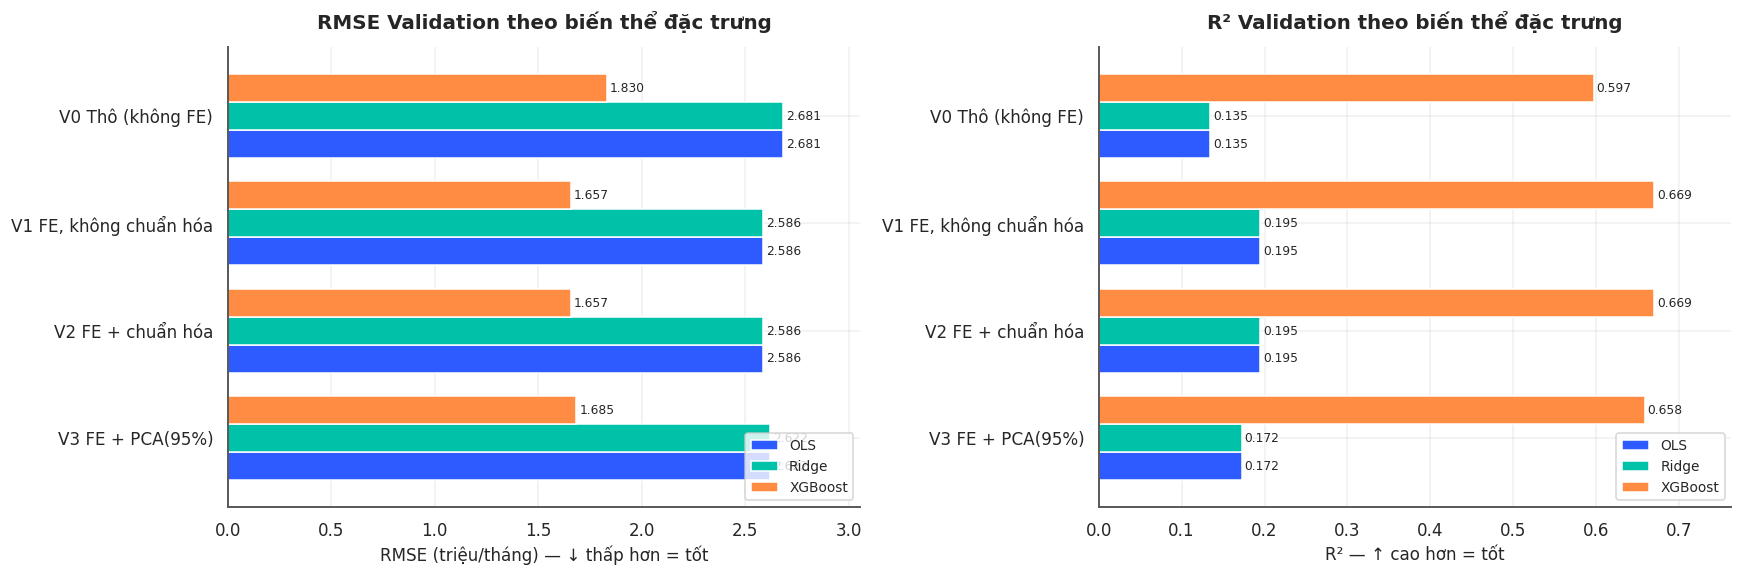

Kết luận thí nghiệm A (đọc từ số liệu):
  • OLS     : Thô→FE giảm RMSE   3.5%  |  thêm PCA làm RMSE tăng  1.4%  |  bỏ chuẩn hóa làm RMSE giảm/không đổi  0.0%
  • Ridge   : Thô→FE giảm RMSE   3.5%  |  thêm PCA làm RMSE tăng  1.4%  |  bỏ chuẩn hóa làm RMSE tăng  0.0%
  • XGBoost : Thô→FE giảm RMSE   9.5%  |  thêm PCA làm RMSE tăng  1.7%  |  bỏ chuẩn hóa làm RMSE giảm/không đổi  0.0%
  → FE (tách city/district từ full_address) là nguồn cải thiện chính — đúng trọng tâm
    đề tài 'theo khu vực'. OLS/XGBoost bất biến với phép co giãn nên chuẩn hóa không đổi
    kết quả của chúng; chuẩn hóa vẫn cần cho mô hình có phạt (Ridge/LASSO) để phạt công
    bằng giữa các hệ số, và để PCA không bị biến có thang đo lớn lấn át.


In [16]:
# Biểu đồ đối sánh 4 biến thể đặc trưng × 3 mô hình
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))
for ax, tbl, ttl, xlab in [(axes[0], rmse_tbl, "RMSE Validation theo biến thể đặc trưng",
                            "RMSE (triệu/tháng) — ↓ thấp hơn = tốt"),
                           (axes[1], r2_tbl, "R² Validation theo biến thể đặc trưng",
                            "R² — ↑ cao hơn = tốt")]:
    tbl.iloc[::-1].plot.barh(ax=ax, color=PALETTE[:3], width=0.78)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    ax.set_title(ttl); ax.set_xlabel(xlab); ax.set_ylabel("")
    ax.legend(title="", loc="lower right", fontsize=9)
    ax.margins(x=0.14)
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "04_ablation_fe_pca.png"); plt.show()

V0, V1, V2, V3 = list(VARIANTS)
print("Kết luận thí nghiệm A (đọc từ số liệu):")
for m in ABL_MODELS:
    d_fe  = (rmse_tbl.loc[V0, m] - rmse_tbl.loc[V2, m]) / rmse_tbl.loc[V0, m] * 100
    d_pca = (rmse_tbl.loc[V3, m] - rmse_tbl.loc[V2, m]) / rmse_tbl.loc[V2, m] * 100
    d_sc  = (rmse_tbl.loc[V1, m] - rmse_tbl.loc[V2, m]) / rmse_tbl.loc[V2, m] * 100
    print(f"  • {m:8s}: Thô→FE giảm RMSE {d_fe:5.1f}%  |  thêm PCA làm RMSE "
          f"{'tăng' if d_pca > 0 else 'giảm'} {abs(d_pca):4.1f}%  |  "
          f"bỏ chuẩn hóa làm RMSE {'tăng' if d_sc > 0 else 'giảm/không đổi'} {abs(d_sc):4.1f}%")
print("  → FE (tách city/district từ full_address) là nguồn cải thiện chính — đúng trọng tâm")
print("    đề tài 'theo khu vực'. OLS/XGBoost bất biến với phép co giãn nên chuẩn hóa không đổi")
print("    kết quả của chúng; chuẩn hóa vẫn cần cho mô hình có phạt (Ridge/LASSO) để phạt công")
print("    bằng giữa các hệ số, và để PCA không bị biến có thang đo lớn lấn át.")

### 11.2. Thí nghiệm B — Mục tiêu `price` gốc ↔ `log1p(price)`

Giảng viên **e ngại** việc log biến mục tiêu: các giá cao đều có **nguyên nhân thực** (vị trí
trung tâm, căn hộ cao cấp…); nén chúng bằng log có thể làm mô hình **underweight phân khúc giá
cao** → dự đoán hụt. Yêu cầu: *chạy thực nghiệm đối sánh xem log có thực sự tăng hiệu năng không*.

**Thiết kế:** cùng pipeline đặc trưng V2, cùng 3 mô hình; chỉ đổi mục tiêu huấn luyện
(`price` ↔ `log1p(price)` qua `TransformedTargetRegressor` — dự đoán **tự đổi ngược** về
triệu/tháng nên chỉ số luôn cùng đơn vị). Ngoài MAE/RMSE/R² toàn cục, ta đo riêng **phân khúc
giá cao (≥ 10 triệu/tháng)**:
- `RMSE giá cao` — sai số trên phân khúc đắt;
- `Bias giá cao` = trung bình (dự đoán − thực tế): **âm nhiều ⇒ dự đoán hụt hệ thống** — chính là
  hiện tượng *underweight* giảng viên cảnh báo.


In [17]:
HI = 10                                  # ngưỡng "giá cao": ≥ 10 triệu/tháng
hi_mask = (y_val >= HI).values
print(f"Phân khúc giá cao (≥{HI} triệu): {hi_mask.sum():,}/{len(y_val):,} mẫu Validation "
      f"({hi_mask.mean()*100:.1f}%)")

abl_log = {}
t0 = time.time()
for mname, mk in ABL_MODELS.items():
    for tname in ["price (gốc)", "log1p(price)"]:
        core = Pipeline([("prep", build_prep(impute_bin=(mname != "XGBoost"))), ("m", mk())])
        model = (TransformedTargetRegressor(regressor=core, func=np.log1p, inverse_func=np.expm1)
                 if tname.startswith("log") else core)
        model.fit(X_train, y_train)
        pred = model.predict(X_val)
        abl_log[(mname, tname)] = {
            "MAE":  mean_absolute_error(y_val, pred),
            "RMSE": root_mean_squared_error(y_val, pred),
            "R²":   r2_score(y_val, pred),
            "RMSE giá cao": root_mean_squared_error(y_val[hi_mask], pred[hi_mask]),
            "Bias giá cao": float((pred[hi_mask] - y_val[hi_mask].values).mean()),
        }
print(f"6 cấu hình (3 mô hình × 2 mục tiêu) xong trong {time.time()-t0:.0f}s.\n")

logdf = pd.DataFrame(abl_log).T
logdf.index.names = ["Mô hình", "Mục tiêu"]
display(logdf.style.format("{:.4f}")
        .background_gradient(subset=["RMSE", "MAE", "RMSE giá cao"], cmap="crest_r")
        .background_gradient(subset=["R²"], cmap="crest")
        .set_caption(f"Đối sánh mục tiêu price ↔ log1p(price) — Bias giá cao < 0 ⇒ dự đoán HỤT phân khúc ≥{HI} triệu"))

Phân khúc giá cao (≥10 triệu): 1,680/19,985 mẫu Validation (8.4%)


6 cấu hình (3 mô hình × 2 mục tiêu) xong trong 98s.



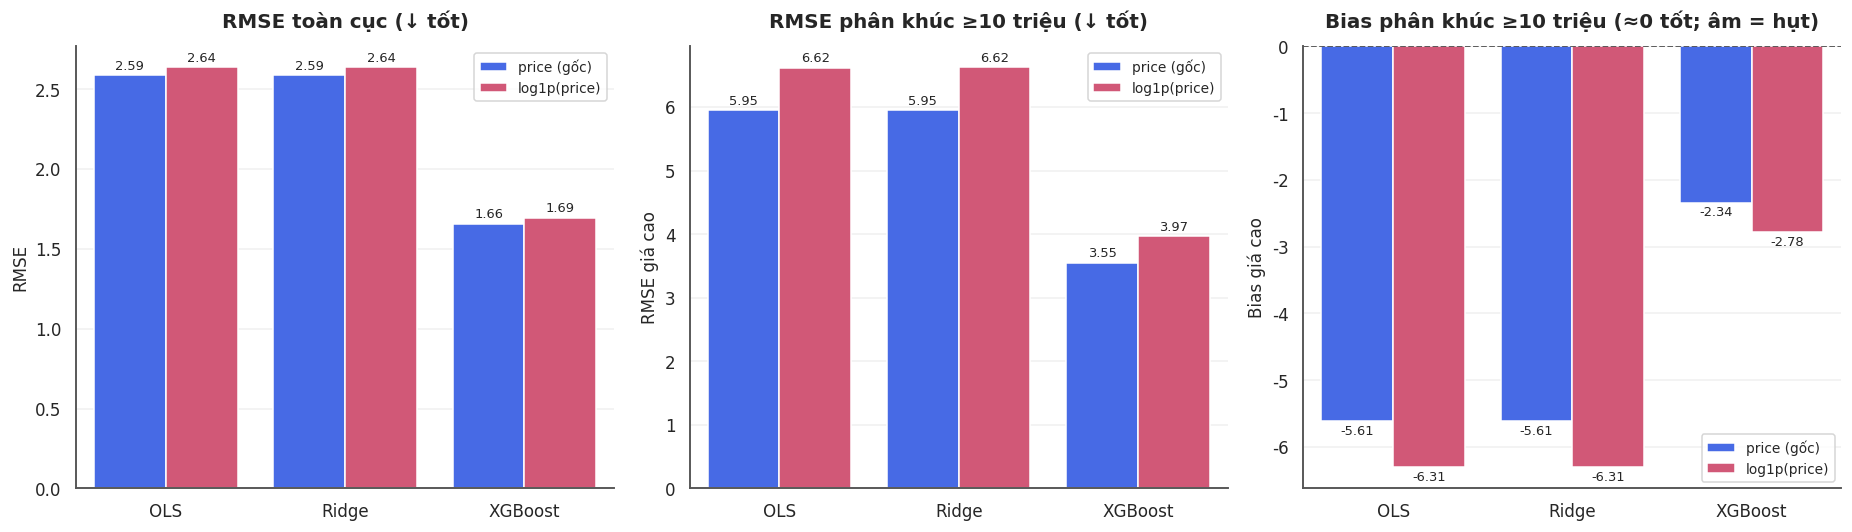

Kết luận thí nghiệm B (đọc từ số liệu):
  • OLS     : log làm MAE giảm 4.1% NHƯNG RMSE tăng 1.9% (2.586 → 2.636); bias giá cao sâu hơn: -5.61 → -6.31 triệu
  • Ridge   : log làm MAE giảm 4.1% NHƯNG RMSE tăng 1.9% (2.586 → 2.636); bias giá cao sâu hơn: -5.61 → -6.31 triệu
  • XGBoost : log làm MAE giảm 1.6% NHƯNG RMSE tăng 2.2% (1.657 → 1.694); bias giá cao sâu hơn: -2.34 → -2.78 triệu
  → Log KHÔNG tăng hiệu năng theo tiêu chí chọn mô hình (RMSE/R²) và NÉN phân khúc giá cao
    (bias âm sâu hơn = dự đoán hụt hệ thống — đúng hiện tượng 'underweight' giảng viên cảnh
    báo). Cải thiện duy nhất là MAE vài %, do log ưu tiên sai số tương đối ở vùng giá phổ biến.
  → QUYẾT ĐỊNH THIẾT KẾ (áp dụng cho mục 3–8): cả 5 mô hình học trên price GỐC. Gợi ý log
    từ EDA 5.2 bị thực nghiệm bác bỏ — minh chứng cho giá trị của việc đối sánh bằng số liệu
    thay vì chỉ dựa vào lập luận về phân phối.


In [18]:
# Biểu đồ: RMSE toàn cục & RMSE/Bias phân khúc giá cao theo mục tiêu huấn luyện
plot_t = logdf.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, ttl in [(axes[0], "RMSE", "RMSE toàn cục (↓ tốt)"),
                     (axes[1], "RMSE giá cao", f"RMSE phân khúc ≥{HI} triệu (↓ tốt)"),
                     (axes[2], "Bias giá cao", f"Bias phân khúc ≥{HI} triệu (≈0 tốt; âm = hụt)")]:
    sns.barplot(data=plot_t, x="Mô hình", y=col, hue="Mục tiêu",
                palette=[PALETTE[0], PALETTE[3]], ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=8.5, padding=2)
    ax.set_title(ttl); ax.set_xlabel(""); ax.set_ylabel(col)
    if col == "Bias giá cao":
        ax.axhline(0, color="#333", lw=1, ls="--")
    ax.legend(fontsize=9, title="")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "05_ablation_log_target.png"); plt.show()

print("Kết luận thí nghiệm B (đọc từ số liệu):")
for m in ABL_MODELS:
    row_r, row_l = logdf.loc[(m, "price (gốc)")], logdf.loc[(m, "log1p(price)")]
    d_mae  = (row_r["MAE"] - row_l["MAE"]) / row_r["MAE"] * 100      # >0: log cải thiện MAE
    d_rmse = (row_l["RMSE"] - row_r["RMSE"]) / row_r["RMSE"] * 100   # >0: log làm RMSE tệ hơn
    print(f"  • {m:8s}: log làm MAE {'giảm' if d_mae > 0 else 'tăng'} {abs(d_mae):.1f}% "
          f"NHƯNG RMSE {'tăng' if d_rmse > 0 else 'giảm'} {abs(d_rmse):.1f}% "
          f"({row_r['RMSE']:.3f} → {row_l['RMSE']:.3f}); "
          f"bias giá cao sâu hơn: {row_r['Bias giá cao']:+.2f} → {row_l['Bias giá cao']:+.2f} triệu")
print("  → Log KHÔNG tăng hiệu năng theo tiêu chí chọn mô hình (RMSE/R²) và NÉN phân khúc giá cao")
print("    (bias âm sâu hơn = dự đoán hụt hệ thống — đúng hiện tượng 'underweight' giảng viên cảnh")
print("    báo). Cải thiện duy nhất là MAE vài %, do log ưu tiên sai số tương đối ở vùng giá phổ biến.")
print("  → QUYẾT ĐỊNH THIẾT KẾ (áp dụng cho mục 3–8): cả 5 mô hình học trên price GỐC. Gợi ý log")
print("    từ EDA 5.2 bị thực nghiệm bác bỏ — minh chứng cho giá trị của việc đối sánh bằng số liệu")
print("    thay vì chỉ dựa vào lập luận về phân phối.")

### 11.3. Thí nghiệm C — Có ↔ không lọc outlier

Bước 2 đã lọc `price ≤ 17` & `area ≤ 180` (ngưỡng chọn từ phân tích EDA — đúng phạm vi *nhà
trọ/căn hộ bình dân* của đề tài). Giảng viên lưu ý: *"nếu một căn nhà tự nhiên có giá vọt lên
1.000 tỷ thì nên bỏ, vì giữ lại sẽ làm sai lệch mô hình"* — thí nghiệm này **hậu kiểm** quyết
định đó bằng số liệu.

**Thiết kế công bằng:** dùng bản dữ liệu **trước khi lọc** (`rental_data.csv` — sản phẩm trung
gian Bước 2 v2), chia Train/Validation cùng `random_state`; hai mô hình XGBoost (siêu tham số
đóng băng) chỉ khác nhau ở **tập Train**: (a) giữ nguyên outlier, (b) đã lọc outlier. Cả hai được
chấm trên **cùng một tập Validation đã lọc về vùng giá mục tiêu** (≤17 triệu, ≤180 m² — vùng mà
bài toán & app demo nhắm tới), nên chênh lệch chỉ đến từ việc *Train có hay không có outlier*.


In [19]:
raw_full = pd.read_csv(DATA / "rental_data.csv", low_memory=False)
raw_full = raw_full.dropna(subset=["price", "area"])
X_raw, y_raw, _ = F.build_Xy(raw_full)

out_mask_all = (y_raw > 17) | (X_raw["area"] > 180)
print(f"Bản CHƯA lọc outlier: {len(y_raw):,} dòng | giá max = {y_raw.max():,.0f} triệu/tháng "
      f"(≈ {y_raw.max()/1000:.1f} TỶ/tháng!) | diện tích max = {X_raw['area'].max():,.0f} m²")
print(f"Outlier theo tiêu chí Bước 2 (price>17 hoặc area>180): {out_mask_all.sum():,} dòng "
      f"({out_mask_all.mean()*100:.1f}%)")

# Chia cùng sơ đồ 70/15/15 (random_state=42) trên dữ liệu CHƯA lọc
Xr_tv, Xr_test, yr_tv, yr_test = train_test_split(X_raw, y_raw, test_size=0.15,
                                                  random_state=RANDOM_STATE)
Xr_tr, Xr_val, yr_tr, yr_val = train_test_split(Xr_tv, yr_tv, test_size=0.176,
                                                random_state=RANDOM_STATE)

# Tập Validation CHUNG: lọc về vùng giá mục tiêu để chấm cả 2 mô hình trên cùng một thước đo
m_val = (yr_val <= 17) & (Xr_val["area"] <= 180)
Xv_c, yv_c = Xr_val[m_val], yr_val[m_val]
m_tr = (yr_tr <= 17) & (Xr_tr["area"] <= 180)
print(f"\nTrain CÓ outlier: {len(yr_tr):,} | Train ĐÃ lọc: {m_tr.sum():,} "
      f"| Validation chung (vùng mục tiêu): {len(yv_c):,}")

abl_out = {}
t0 = time.time()
for label, (Xt, yt) in {
        "Train CÓ outlier":    (Xr_tr, yr_tr),
        "Train ĐÃ lọc outlier": (Xr_tr[m_tr], yr_tr[m_tr])}.items():
    pipe = Pipeline([("prep", build_prep()), ("m", make_xgb_best())]).fit(Xt, yt)
    abl_out[label] = evaluate(pipe, Xv_c, yv_c)
print(f"2 cấu hình XGBoost xong trong {time.time()-t0:.0f}s.\n")

outdf = pd.DataFrame(abl_out).T.rename(columns={"R2": "R²"})
display(outdf.style.format("{:.4f}")
        .background_gradient(subset=["RMSE", "MAE"], cmap="crest_r")
        .background_gradient(subset=["R²"], cmap="crest")
        .set_caption("XGBoost — cùng Validation (vùng giá mục tiêu), chỉ khác tập Train"))

Bản CHƯA lọc outlier: 147,955 dòng | giá max = 10,000 triệu/tháng (≈ 10.0 TỶ/tháng!) | diện tích max = 1,000 m²
Outlier theo tiêu chí Bước 2 (price>17 hoặc area>180): 10,074 dòng (6.8%)

Train CÓ outlier: 103,627 | Train ĐÃ lọc: 96,628 | Validation chung (vùng mục tiêu): 20,623


2 cấu hình XGBoost xong trong 98s.



,MAE,RMSE,R²
Train CÓ outlier,2.1280,9.7467,-10.8285
Train ĐÃ lọc outlier,0.9887,1.6517,0.6603


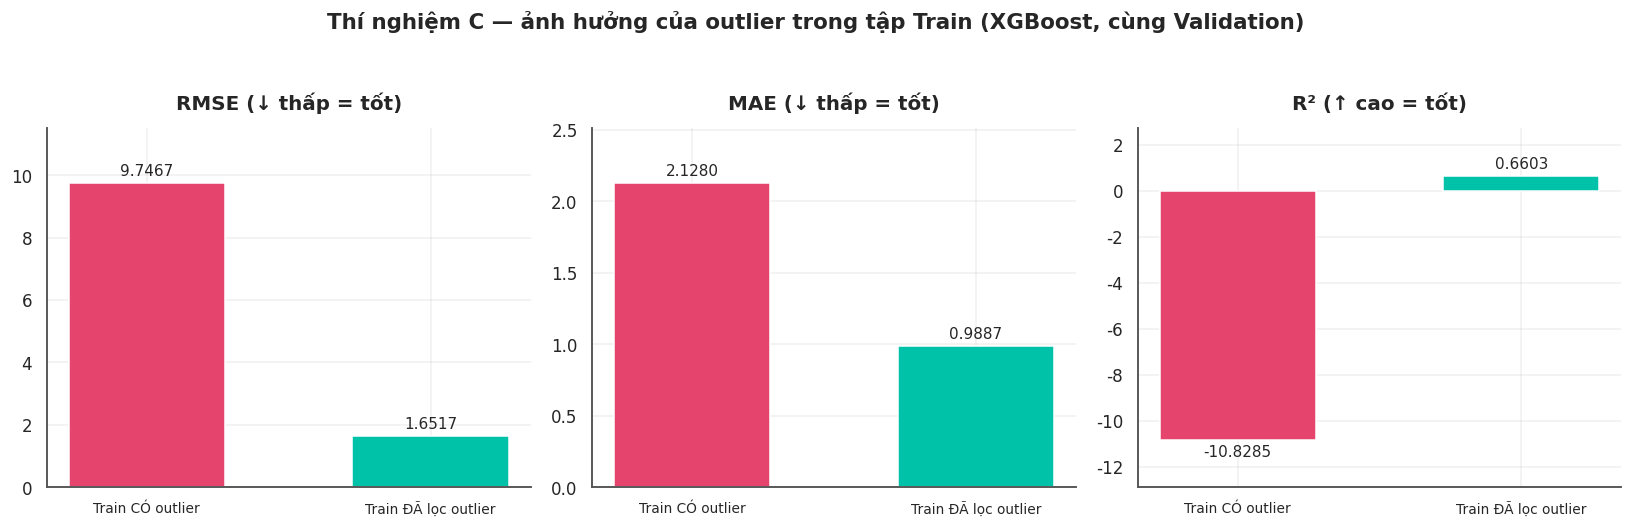

Kết luận thí nghiệm C (đọc từ số liệu):
  • Lọc outlier khỏi Train làm RMSE trên vùng giá mục tiêu GIẢM 83.1% (9.7467 → 1.6517).
  • Khớp nhận định của giảng viên: vài bản ghi giá hàng trăm triệu–hàng tỷ/tháng kéo lệch
    hàm mất mát (bình phương sai số), làm mô hình phân bổ năng lực cho vùng giá không thuộc
    phạm vi bài toán ⇒ quyết định lọc outlier ở Bước 2 được số liệu xác nhận.


In [20]:
# Biểu đồ đối sánh có/không lọc outlier + kết luận
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, col, better in [(axes[0], "RMSE", "↓ thấp = tốt"), (axes[1], "MAE", "↓ thấp = tốt"),
                        (axes[2], "R²", "↑ cao = tốt")]:
    bars = ax.bar(outdf.index, outdf[col], color=[PALETTE[3], PALETTE[1]], width=0.55)
    ax.bar_label(bars, fmt="%.4f", fontsize=10, padding=3)
    ax.set_title(f"{col} ({better})"); ax.tick_params(axis="x", labelsize=9)
    ax.margins(y=0.18)
fig.suptitle("Thí nghiệm C — ảnh hưởng của outlier trong tập Train (XGBoost, cùng Validation)",
             y=1.04, fontsize=14, fontweight="bold")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "06_ablation_outliers.png"); plt.show()

d = (abl_out["Train CÓ outlier"]["RMSE"] - abl_out["Train ĐÃ lọc outlier"]["RMSE"]) \
    / abl_out["Train CÓ outlier"]["RMSE"] * 100
print("Kết luận thí nghiệm C (đọc từ số liệu):")
print(f"  • Lọc outlier khỏi Train làm RMSE trên vùng giá mục tiêu "
      f"{'GIẢM' if d > 0 else 'TĂNG'} {abs(d):.1f}% "
      f"({abl_out['Train CÓ outlier']['RMSE']:.4f} → {abl_out['Train ĐÃ lọc outlier']['RMSE']:.4f}).")
print("  • Khớp nhận định của giảng viên: vài bản ghi giá hàng trăm triệu–hàng tỷ/tháng kéo lệch")
print("    hàm mất mát (bình phương sai số), làm mô hình phân bổ năng lực cho vùng giá không thuộc")
print("    phạm vi bài toán ⇒ quyết định lọc outlier ở Bước 2 được số liệu xác nhận.")

## 12. Lưu mô hình & metadata

Lưu **toàn bộ pipeline** (tiền xử lý + mô hình) của từng thuật toán bằng `joblib` (nén `compress=3`),
đánh dấu mô hình tốt nhất là `model_best.pkl`, kèm `metadata.json` (danh sách cột, siêu tham số,
chỉ số Validation, phiên bản thư viện) để **app demo Bước 6** nạp lại và dự đoán nhất quán.
Tất cả ghi vào `v2/models/`.

> ⚠️ `model_random_forest.pkl` rất lớn (500 cây × depth lớn ≈ 95 MB sau nén) → nên **`.gitignore`**
> để không vượt giới hạn 100 MB của GitHub. Mô hình này **tái tạo được** từ `best_params` trong
> `metadata.json` (chỉ 1 lần `fit`). `model_best.pkl` (XGBoost ≈ 1 MB) vẫn được commit bình thường.


In [21]:
fname = {"OLS": "ols", "Ridge": "ridge", "LASSO": "lasso",
         "Random Forest": "random_forest", "XGBoost": "xgboost"}
for name, model in models.items():
    joblib.dump(model, MODELS / f"model_{fname[name]}.pkl", compress=3)
joblib.dump(models[BEST_NAME], MODELS / "model_best.pkl", compress=3)

best_params = {
    "Ridge": ridge_gs.best_params_,
    "LASSO": lasso_gs.best_params_,
    "Random Forest": rf_search.best_params_,
    "XGBoost": {**xgb_search.best_params_, "early_stop_best_iteration": int(xgb_final.best_iteration)},
}
metadata = {
    "task": "regression - du bao gia thue (trieu VND/thang)",
    "target": F.TARGET,
    "data_source": "v2/data/processed/rental_data_clean.csv (Buoc 2 - notebook 02 v2)",
    "best_model": BEST_NAME,                 # mo hinh duoc LUU/trien khai (model_best.pkl)
    "most_accurate_val": MOST_ACCURATE,      # RMSE thap nhat; co the != best_model (XGBoost rang buoc, gon)
    "feature_columns": {"num": COL_GROUPS["num"], "cat": COL_GROUPS["cat"], "bin": COL_GROUPS["bin"]},
    "split": {"train": len(X_train), "val": len(X_val), "test": len(X_test), "scheme": "70/15/15"},
    "validation_metrics": {k: {m: round(float(val), 4) for m, val in v.items()} for k, v in results.items()},
    "best_params": best_params,
    "versions": {"scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__},
    "excluded_features": ["source", "n_features", "price_per_m2", "log_price", "posted_date", "description"],
    "mnar_fix": {     # co tien ich che tac -> NaN; XGBoost rang buoc don dieu (kiem toan Buoc 2 v2)
        "observed_flags_by_source": {k: len(v) for k, v in F.OBSERVED_FLAGS.items()},
        "monotone_constraints": "12 co feature_* : +1 (khong am khi tick tien ich)",
    },
    "ablation": {   # muc 11 — thuc nghiem doi sanh theo gop y giang vien (RMSE/R2 tren Validation)
        "fe_pca_rmse": {f"{v} | {m}": round(float(r["RMSE"]), 4) for (v, m), r in abl_fe.items()},
        "log_target": {f"{m} | {t}": {kk: round(float(vv), 4) for kk, vv in r.items()}
                       for (m, t), r in abl_log.items()},
        "outliers_xgb": {k: {kk: round(float(vv), 4) for kk, vv in r.items()}
                         for k, r in abl_out.items()},
    },
    "note": "source CO Y bi loai (artifact thu thap, khong phai yeu to dinh gia). "
            "n_features bi loai + 7/12 co tien ich che tac bi mask NaN theo nguon (MNAR, xem "
            "features.OBSERVED_FLAGS; kiem toan o Buoc 2 - notebook 02 v2); XGBoost them "
            "monotone_constraints cho 12 co. Test set chua dung — danh cho Buoc 5. "
            "FE dung v2/script/model/features.py. Muc 11: ablation FE/PCA, log-target, outlier.",
}
(MODELS / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

print("Đã lưu vào", MODELS)
for p in sorted(MODELS.glob("*")):
    print(f"  • {p.name:28s} {p.stat().st_size/1024:8.1f} KB")

Đã lưu vào /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/models
  • metadata.json                     4.7 KB
  • model_best.pkl                 1106.7 KB
  • model_lasso.pkl                   7.9 KB
  • model_ols.pkl                     8.6 KB
  • model_random_forest.pkl        5690.0 KB
  • model_ridge.pkl                   8.0 KB
  • model_xgboost.pkl              1106.7 KB


## 13. Tổng kết Bước 4 & bàn giao Bước 5

**Đã hoàn thành (đúng yêu cầu Bước 4):**
1. Chuẩn bị `X`/`y`, chia **Train/Val/Test = 70/15/15** (Test giữ nguyên cho Bước 5).
2. Huấn luyện **5 mô hình**: OLS, Ridge, LASSO, Random Forest, XGBoost.
3. **Tinh chỉnh siêu tham số**: GridSearchCV (tuyến tính) + RandomizedSearchCV (cây) + early
   stopping cho XGBoost.
4. **Feature Importance** (RF MDI + XGBoost gain) — đối chiếu, kiểm chứng phát hiện EDA.
5. **Thực nghiệm đối sánh (mục 11, theo góp ý giảng viên)**: thô↔FE↔FE+PCA (kèm có/không
   chuẩn hóa), `price`↔`log(price)`, có↔không lọc outlier.
6. **Lưu** mô hình triển khai `v2/models/model_best.pkl` + `metadata.json` (kèm kết quả ablation).

**Khám phá chính:**
- **Mô hình triển khai = XGBoost có ràng buộc đơn điệu** (Quyết định D — bảo đảm *"tick tiện ích
  không làm giảm giá"*). Random Forest chạy không ràng buộc có thể đạt RMSE thô thấp hơn, nhưng
  phần chênh đến từ khai thác tương quan hành-vi-đăng-tin phi nhân quả, và RF nặng ≈100 MB (vượt
  giới hạn GitHub) so với ≈2 MB của XGBoost ⇒ XGBoost vừa gọn vừa đúng hành vi cho app demo.
- Mô hình **cây (Random Forest / XGBoost)** vượt trội mô hình tuyến tính ⇒ quan hệ giá↔đặc trưng
  **phi tuyến** và có **tương tác khu vực × diện tích** mạnh (khớp PCA/heatmap ở EDA).
- **Cố ý loại `source`** (artifact thu thập, không phải yếu tố định giá thực) và **mask MNAR**
  7/12 cờ tiện ích chế tác + bỏ `n_features` (kiểm toán ở Bước 2 — notebook 02 v2). Chỉ số có thể
  thấp hơn bản chưa làm sạch, NHƯNG mô hình **tổng quát và trung thực hơn** — dự báo từ đặc điểm
  BĐS thật, đúng kịch bản app demo.
- Đặc trưng quan trọng nhất là **khu vực** (`city`/`district`), **diện tích** (`area`) — diễn
  giải rõ ràng, đúng nghiệp vụ.
- LASSO loại bớt các chiều One-Hot hiếm ⇒ xác nhận nhiều quận/tiện ích đóng góp biên nhỏ.

**Kết luận từ thực nghiệm đối sánh (mục 11 — số liệu cụ thể in trong từng thí nghiệm):**
- **FE > thô:** tách `city`/`district` từ `full_address` là nguồn cải thiện chính — dữ liệu thô
  mất toàn bộ tín hiệu khu vực. **PCA không cải thiện thêm** trên dữ liệu này (giá trị của FE ở
  đây là *mở khóa* thông tin địa chỉ, không phải tăng chiều).
- **Chuẩn hóa:** không đổi kết quả với OLS/XGBoost (bất biến co giãn) nhưng cần cho mô hình
  có phạt (Ridge/LASSO) và cho PCA — giữ trong pipeline như khuyến nghị của giảng viên.
- **Log mục tiêu:** KHÔNG tăng hiệu năng — chỉ cải thiện MAE vài %, còn RMSE/R² tệ hơn và
  **bias âm sâu hơn ở phân khúc giá cao** (dự đoán hụt — đúng lo ngại *underweight* của giảng
  viên) ⇒ **cả 5 mô hình học trên `price` gốc**; gợi ý log từ EDA bị thực nghiệm bác bỏ.
- **Lọc outlier:** huấn luyện kèm outlier (giá tới hàng tỷ/tháng) làm hiệu năng trên vùng giá
  mục tiêu xấu đi rõ rệt ⇒ xác nhận quyết định lọc `price≤17`, `area≤180` ở Bước 2.

**Bàn giao Bước 5 (Đánh giá & Lựa chọn mô hình — Slide L12):**
- Chạy **10-fold Cross-Validation** trên Train để báo cáo độ ổn định (mean ± std).
- **Đánh giá cuối cùng 1 lần trên tập Test** (Model Assessment): MAE / RMSE / R².
- Vẽ **Actual vs Predicted** & **Residual plot** trên Test; hoàn thiện **bảng so sánh** mô hình.
- Mô hình & metadata đã sẵn trong `v2/models/` để Bước 5 nạp lại, không cần huấn luyện lại.
